# Chapitre 2 - Cours 2 : Taille des modèles, calcul et lois d'échelle

Quand un nouveau modèle sort, la première question est souvent « combien de
paramètres ? ». Ce notebook donne les outils pour répondre, et surtout pour en tirer les
conséquences pratiques : mémoire, coût d'entraînement, choix entre taille du modèle et
quantité de données. Il couvre :

- la fin de la section *Model Architecture* : dimensions d'un transformer (tableau 2-4
  du livre), prefill et decode, architectures alternatives (*Other model architectures* :
  RWKV, SSM, Mamba, Jamba) ;
- la section *Model Size* : paramètres, parcimonie et mélange d'experts, tokens
  d'entraînement, FLOPs, coût ; puis *Scaling law: Building compute-optimal models*
  (Chinchilla), *Scaling extrapolation* et *Scaling bottlenecks*.

**Plan.** 1. Compter les paramètres à partir de la configuration ; 2. Mémoire : poids et
cache KV ; 3. Prefill et decode ; 4. Au-delà du transformer ; 5. Parcimonie et mélange
d'experts ; 6. Tokens, FLOPs et dollars ; 7. La loi de Chinchilla ; 8. Extrapolation et
capacités émergentes ; 9. Les goulots d'étranglement ; Synthèse.

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoConfig

from aie import llm
from aie import ch02_modeles as m
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, subtitle, finish)

set_style()
warnings.filterwarnings("ignore", category=FutureWarning)
llm.seed_everything(0)
rng = np.random.default_rng(0)
pd.set_option("display.precision", 2)
sci = lambda v: f"{v:.0e}".replace("e+", "e")   # étiquettes compactes pour les axes log
big = lambda n: f"{n / 1e9:.2f} G" if n >= 1e9 else f"{n / 1e6:.1f} M"

## 1. Compter les paramètres à partir de la configuration (section *Model Architecture*)

La taille d'un transformer décodeur est entièrement fixée par quelques hyperparamètres
(cours 1, section 9) : la dimension du modèle $d$, le nombre de blocs $L$, la dimension
du MLP $d_{ff}$, la taille du vocabulaire $V$, et le nombre de têtes de requêtes $h$ et de
têtes clés-valeurs $h_{kv}$ (avec $d_h = d/h$). En négligeant biais et normalisations :

| composant | paramètres |
|---|---|
| plongements | $V d$ |
| attention, par bloc | $\underbrace{d^2}_{W_Q} + \underbrace{2\,d\,h_{kv} d_h}_{W_K, W_V} + \underbrace{d^2}_{W_O}$ |
| MLP, par bloc | $2\,d\,d_{ff}$ (classique, GPT-2) ou $3\,d\,d_{ff}$ (SwiGLU, Llama, Qwen) |
| tête de sortie | $V d$, ou 0 si elle **partage** la matrice des plongements (*tied*) |

Pour Llama 2-7B ($d = 4096$, $L = 32$, $d_{ff} = 11\,008$, $V = 32\,000$, $h_{kv} = h$) :
$$N \approx 32\,(4 \cdot 4096^2 + 3 \cdot 4096 \cdot 11\,008) + 2 \cdot 32\,000 \cdot 4096
\approx 6{,}48\text{ G} + 0{,}26\text{ G} = 6{,}74 \text{ milliards}.$$

La fonction `m.count_params_config` implémente le calcul exact (biais et normalisations
compris). Vérifions-la contre les **vrais fichiers de poids** de nos modèles locaux : on lit
uniquement les en-têtes des fichiers `safetensors` (formes des tenseurs), sans charger le
modèle en mémoire.

In [2]:
rows = []
for mid in ["gpt2", "Qwen/Qwen2.5-0.5B", llm.SMALL, llm.MEDIUM]:
    cfg = m.config_from_hf(AutoConfig.from_pretrained(mid), name=mid)
    n_cfg, n_file = m.count_params_config(cfg), m.count_params_safetensors(mid)
    rows.append(dict(modèle=mid, d=cfg.d_model, L=cfg.n_layers, d_ff=cfg.d_ff, V=cfg.vocab, h=cfg.n_heads,
                     h_kv=cfg.kv_heads, calcul_config=f"{n_cfg:,}".replace(",", " "),
                     fichier_poids=f"{n_file:,}".replace(",", " "), écart=n_file - n_cfg))
pd.DataFrame(rows)

,modèle,d,L,d_ff,V,h,h_kv,calcul_config,fichier_poids,écart
0,gpt2,768,12,3072,50257,12,12,124 439 808,137 022 720,12582912
1,Qwen/Qwen2.5-0.5B,896,24,4864,151936,14,2,494 032 768,494 032 768,0
2,Qwen/Qwen2.5-0.5B-Instruct,896,24,4864,151936,14,2,494 032 768,494 032 768,0
3,Qwen/Qwen2.5-1.5B-Instruct,1536,28,8960,151936,12,2,1 543 714 304,1 543 714 304,0


Accord exact pour les trois modèles Qwen2.5. Pour GPT-2, le fichier contient
$12\,582\,912 = 12 \times 1024^2$ valeurs de plus : ce ne sont pas des paramètres, mais
les **masques causaux** $1024 \times 1024$ de chacun des 12 blocs, sauvegardés par
l'ancienne implémentation. Bon réflexe : un « nombre de paramètres » lu dans un fichier
peut inclure des tampons non entraînables.

Appliquons maintenant la formule aux configurations publiques des modèles Llama
(tableau 2-4 du livre) et de Mixtral.

In [3]:
known = ["GPT-2 (124M)", "Qwen2.5-0.5B", "Qwen2.5-1.5B", "Llama 2-7B", "Llama 2-13B", "Llama 2-70B",
         "Llama 3-8B", "Llama 3-70B", "Llama 3.1-405B"]
tab = pd.DataFrame([dict(modèle=k, blocs=c.n_layers, d=c.d_model, d_ff=c.d_ff, V=c.vocab, têtes=c.n_heads,
                         têtes_kv=c.kv_heads, contexte=c.context,
                         paramètres=big(m.count_params_config(c)))
                    for k, c in m.KNOWN_CONFIGS.items() if k in known])
tab

,modèle,blocs,d,d_ff,V,têtes,têtes_kv,contexte,paramètres
0,GPT-2 (124M),12,768,3072,50257,12,12,1024,124.4 M
1,Qwen2.5-0.5B,24,896,4864,151936,14,2,32768,494.0 M
2,Qwen2.5-1.5B,28,1536,8960,151936,12,2,32768,1.54 G
3,Llama 2-7B,32,4096,11008,32000,32,32,4096,6.74 G
4,Llama 2-13B,40,5120,13824,32000,40,40,4096,13.02 G
5,Llama 2-70B,80,8192,28672,32000,64,8,4096,68.98 G
6,Llama 3-8B,32,4096,14336,128256,32,8,8192,8.03 G
7,Llama 3-70B,80,8192,28672,128256,64,8,8192,70.55 G
8,Llama 3.1-405B,126,16384,53248,128256,128,8,131072,405.85 G


Remarque : pour Llama 2-70B, le fichier `config.json` officiel indique
$d_{ff} = 28\,672$ (avec GQA à 8 têtes KV), valeur qui redonne bien 69 milliards de
paramètres. Notez aussi que « Llama 3-8B » compte 8,03 milliards de paramètres, contre
6,74 pour Llama 2-7B à architecture presque identique : la différence vient surtout du
vocabulaire quatre fois plus grand (128 256 tokens) et d'un MLP plus large.

**Où sont les paramètres ?** Répartition par composant :

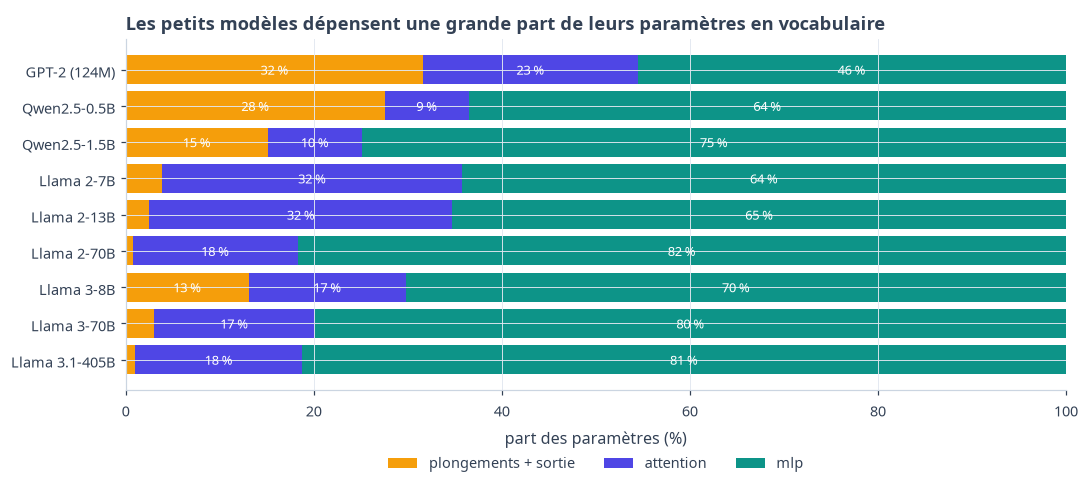

In [4]:
parts = {k: m.param_breakdown(m.KNOWN_CONFIGS[k]) for k in known}
dfp = pd.DataFrame(parts).T
total = dfp.sum(axis=1)
dfp["plongements + sortie"] = dfp["embeddings"] + dfp["positions"] + dfp["tête de sortie"]
frac = dfp[["plongements + sortie", "attention", "mlp"]].div(total, axis=0) * 100
fig, ax = plt.subplots(figsize=(10, 4.6))
left = np.zeros(len(frac))
for col, c in zip(frac.columns, [AMBER, INDIGO, TEAL]):
    ax.barh(frac.index, frac[col], left=left, color=c, label=col)
    for i, (l, v) in enumerate(zip(left, frac[col])):
        if v > 6:
            ax.text(l + v / 2, i, f"{v:.0f} %", ha="center", va="center", color="white", fontsize=8.5)
    left += frac[col].values
ax.invert_yaxis(); ax.set_xlabel("part des paramètres (%)"); ax.set_xlim(0, 100)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.14))
ax.set_title("Les petits modèles dépensent une grande part de leurs paramètres en vocabulaire")
plt.tight_layout(); plt.show()

Les plongements coûtent $Vd$ : un terme **linéaire** en $d$, alors que les blocs coûtent
$\approx 12 L d^2$, **quadratique**. Pour Qwen2.5-0.5B, avec un vocabulaire de 152 000
tokens, plus d'un quart des paramètres sert à la table des plongements (partagée avec la
sortie) ; pour Llama 3.1-405B, c'est moins de 1 %. C'est pourquoi les petits modèles
partagent souvent la matrice d'entrée et de sortie.

> **À retenir.** $N \approx L(4d^2 + 3d\,d_{ff}) + Vd$ (Llama/Qwen, sans GQA). Avec la
> configuration d'un modèle, on retrouve son nombre de paramètres à l'unité près, et on
> sait où ils se trouvent.

## 2. Mémoire : poids et cache KV

**Les poids.** Avec $b$ octets par paramètre, les poids occupent $N \cdot b$ octets :
un modèle de 7 milliards de paramètres en 16 bits demande au moins 14 Go pour
l'inférence (le chapitre 7 détaille le calcul complet, activations comprises, et la
quantification).

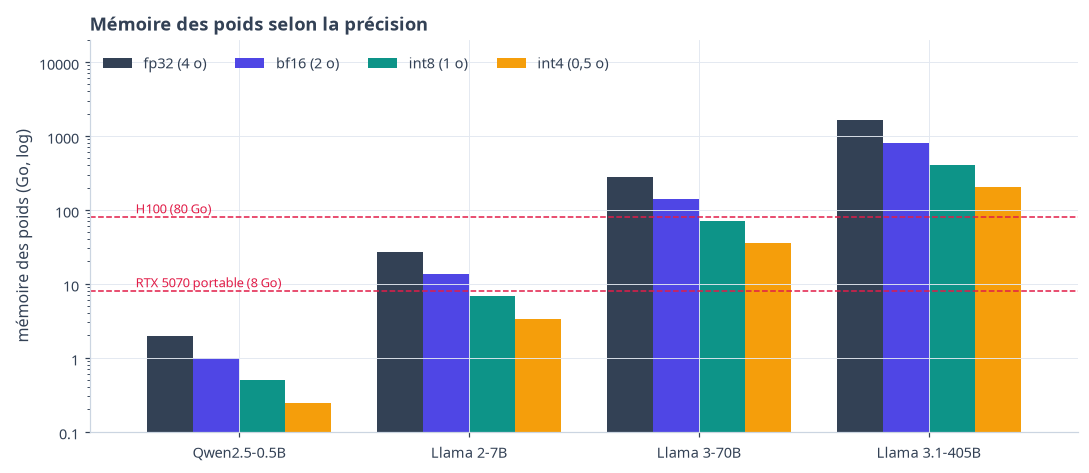

In [5]:
precisions = {"fp32 (4 o)": 4, "bf16 (2 o)": 2, "int8 (1 o)": 1, "int4 (0,5 o)": 0.5}
mods = ["Qwen2.5-0.5B", "Llama 2-7B", "Llama 3-70B", "Llama 3.1-405B"]
mem = pd.DataFrame({p: [m.weights_memory_gb(m.count_params_config(m.KNOWN_CONFIGS[k]), b) for k in mods]
                    for p, b in precisions.items()}, index=mods)
fig, ax = plt.subplots(figsize=(10, 4.4))
mem.plot.bar(ax=ax, color=[SLATE, INDIGO, TEAL, AMBER], width=0.8, rot=0)
ax.set_yscale("log"); m.plain_log_axis(ax, "y")
for gb, lab in [(8, "RTX 5070 portable (8 Go)"), (80, "H100 (80 Go)")]:
    ax.axhline(gb, color=ROSE, ls="--", lw=1); ax.text(-0.45, gb * 1.12, lab, color=ROSE, fontsize=8.5, ha="left")
ax.set_ylabel("mémoire des poids (Go, log)"); ax.set_xlabel("")
ax.set_title("Mémoire des poids selon la précision")
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, 1.0)); ax.set_ylim(0.1, 2e4)
plt.tight_layout(); plt.show()

**Le cache KV.** Pendant la génération, chaque token déjà traité laisse dans chaque
couche un vecteur clé et un vecteur valeur, conservés pour ne pas les recalculer (cours
1, section 6). Leur taille vaut
$$M_{KV} = 2 \times L \times h_{kv} \times d_h \times T \times B \times b \text{ octets}$$
pour $T$ tokens, un batch de $B$ séquences et $b$ octets par valeur. C'est pour cela que
le livre note qu'un contexte plus long n'ajoute aucun paramètre mais augmente l'empreinte
mémoire. Comparons Llama 2-7B (32 têtes KV), Llama 3-8B (GQA, 8 têtes KV) et Qwen2.5-0.5B.

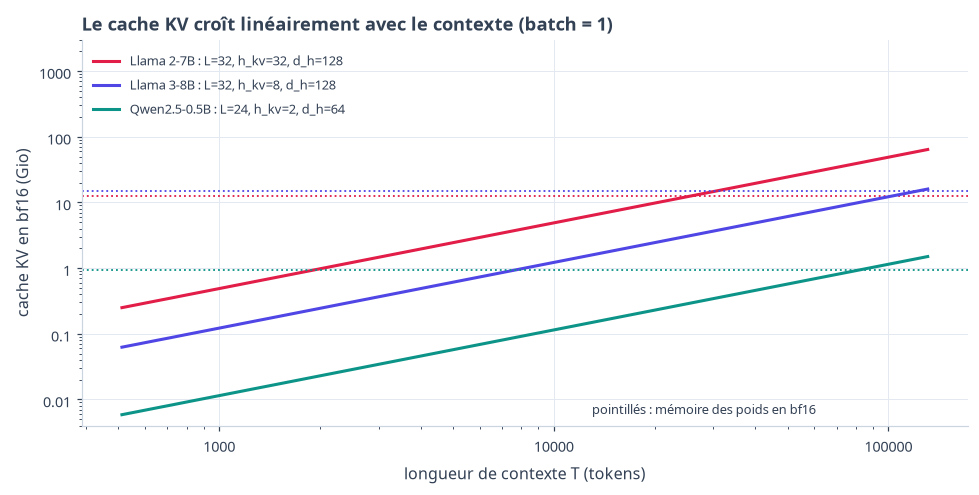

Llama 2-7B : cache KV à 4 096 tokens = 2.00 Gio, à 128 k tokens = 64 Gio
Llama 3-8B : cache KV à 4 096 tokens = 0.50 Gio, à 128 k tokens = 16 Gio


In [6]:
ctx = np.logspace(np.log10(512), np.log10(131072), 50)
fig, ax = plt.subplots(figsize=(9, 4.6))
for k, c in [("Llama 2-7B", ROSE), ("Llama 3-8B", INDIGO), ("Qwen2.5-0.5B", TEAL)]:
    cfg = m.KNOWN_CONFIGS[k]
    ax.loglog(ctx, [m.kv_cache_bytes(cfg, int(t)) / 2 ** 30 for t in ctx], color=c,
              label=f"{k} : L={cfg.n_layers}, h_kv={cfg.kv_heads}, d_h={cfg.head_dim}")
    w_gb = m.weights_memory_gb(m.count_params_config(cfg)) * 1e9 / 2 ** 30
    ax.axhline(w_gb, color=c, ls=":", lw=1.2)
ax.text(1.3e4, 0.006, "pointillés : mémoire des poids en bf16", fontsize=8.5, color=SLATE)
ax.set_xlabel("longueur de contexte T (tokens)"); ax.set_ylabel("cache KV en bf16 (Gio)")
m.plain_log_axis(ax); m.plain_log_axis(ax, "y")
ax.set_title("Le cache KV croît linéairement avec le contexte (batch = 1)")
ax.set_ylim(0.004, 3000)
ax.legend(loc="upper left", fontsize=8.5)
plt.tight_layout(); plt.show()
for k in ["Llama 2-7B", "Llama 3-8B"]:
    print(f"{k} : cache KV à 4 096 tokens = {m.kv_cache_bytes(m.KNOWN_CONFIGS[k], 4096) / 2**30:.2f} Gio, "
          f"à 128 k tokens = {m.kv_cache_bytes(m.KNOWN_CONFIGS[k], 131072) / 2**30:.0f} Gio")

À 128 000 tokens, le cache d'une seule conversation Llama 3-8B (16 Gio) dépasse déjà les
poids du modèle ; sans GQA, il serait quatre fois plus gros. Allonger le contexte d'un
transformer est donc d'abord un problème de **mémoire** (chapitres 7 et 9).

> **À retenir.** Poids : $N \cdot b$. Cache KV : $2 L h_{kv} d_h T B b$, proportionnel au
> contexte et au batch. La GQA (moins de têtes KV) est l'astuce standard pour le réduire.

## 3. Prefill et decode : deux régimes d'inférence

Le cours 1 l'a annoncé : un transformer traite l'**entrée en parallèle** (prefill) mais
**génère séquentiellement** (decode). Le schéma résume les deux phases.

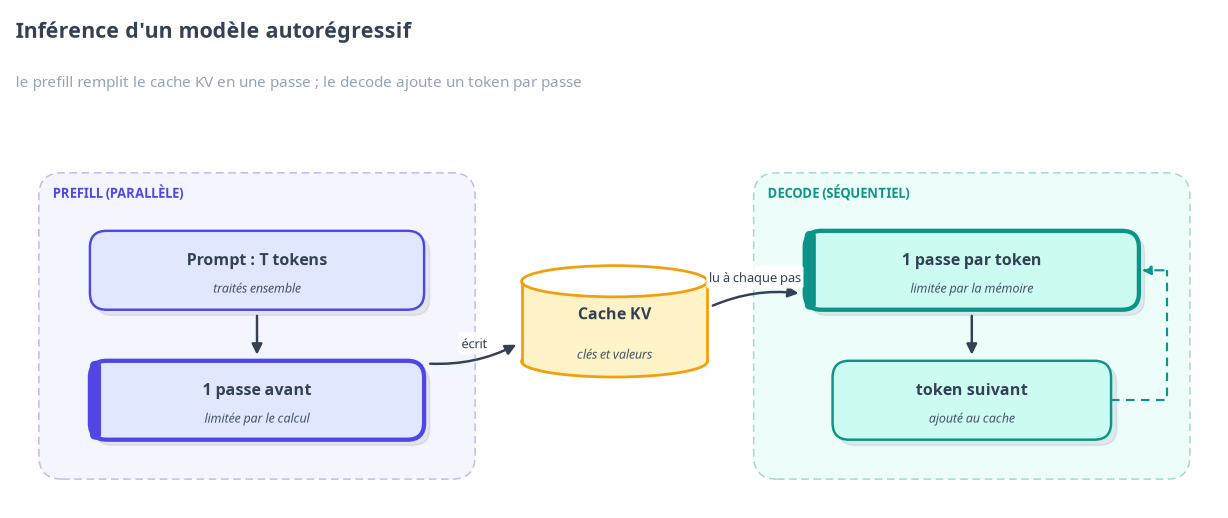

In [7]:
d = Diagram(13, 4.4, title="Inférence d'un modèle autorégressif",
            subtitle="le prefill remplit le cache KV en une passe ; le decode ajoute un token par passe")
d.group(0.3, 0.3, 5.0, 3.6, "prefill (parallèle)", color=INDIGO)
d.box("p", 2.65, 2.55, "Prompt : T tokens", sub="traités ensemble", color=INDIGO, w=3.6, h=0.85)
d.box("f1", 2.65, 1.15, "1 passe avant", sub="limitée par le calcul", color=INDIGO, kind="model", w=3.6, h=0.85)
d.arrow("p", "f1")
d.box("kv", 6.5, 2.0, "Cache KV", sub="clés et valeurs", color=AMBER, kind="db", w=2.0, h=1.2)
d.group(8.0, 0.3, 12.7, 3.6, "decode (séquentiel)", color=TEAL)
d.box("dec", 10.35, 2.55, "1 passe par token", sub="limitée par la mémoire", color=TEAL, kind="model", w=3.6,
      h=0.85)
d.box("tok", 10.35, 1.15, "token suivant", sub="ajouté au cache", color=TEAL, w=3.0, h=0.85)
d.arrow("f1", "kv", "écrit", rad=0.15)
d.arrow("kv", "dec", "lu à chaque pas", rad=-0.15)
d.arrow("dec", "tok")
d.line([(11.85, 1.15), (12.45, 1.15), (12.45, 2.55), (12.15, 2.55)], color=TEAL, style="dashed", lw=1.4)
d.show()

Mesurons-le sur Qwen2.5-0.5B : durée du prefill en fonction de la longueur du prompt, et
durée moyenne d'un pas de decode. Les temps absolus dépendent du matériel (et ici de la
charge du GPU, partagé avec d'autres travaux) ; c'est l'ordre de grandeur qui compte.

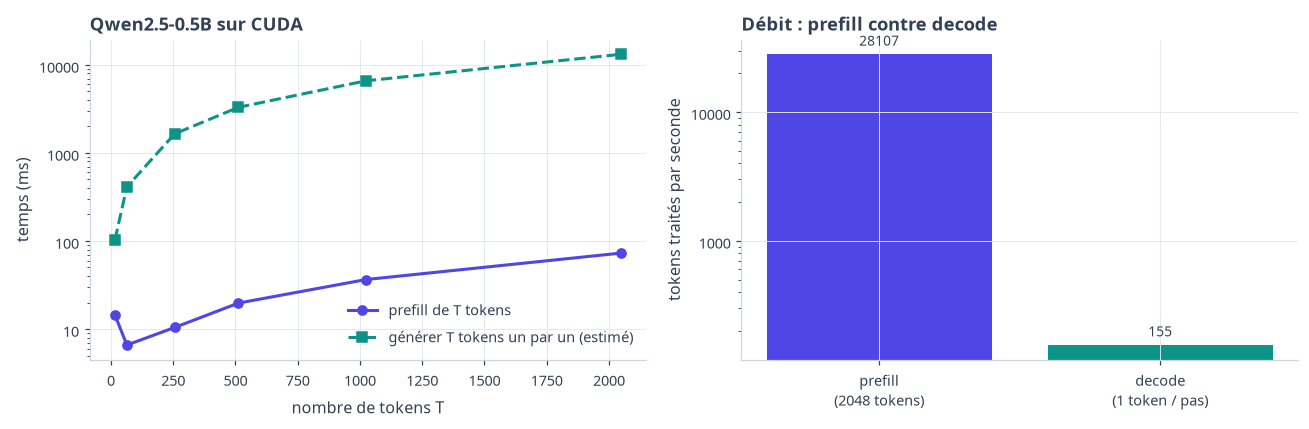

un pas de decode : 6.4 ms ; prefill de 2048 tokens : 73 ms


In [8]:
tok, model = llm.load(llm.SMALL)
dev = model.device


def sync():
    if dev.type == "cuda":
        torch.cuda.synchronize()


base_ids = torch.randint(1000, 20000, (1, 2048), generator=torch.Generator().manual_seed(0)).to(dev)
with torch.no_grad():
    model(base_ids[:, :32])  # échauffement
    prefill = []
    for T in [16, 64, 256, 512, 1024, 2048]:
        sync(); t0 = time.perf_counter()
        for _ in range(3):
            out = model(base_ids[:, :T], use_cache=True)
        sync(); prefill.append((T, (time.perf_counter() - t0) / 3))
    past = model(base_ids[:, :256], use_cache=True).past_key_values
    nxt = base_ids[:, 256:257]
    sync(); t0 = time.perf_counter()
    n_dec = 64
    for _ in range(n_dec):
        o = model(nxt, past_key_values=past, use_cache=True)
        past, nxt = o.past_key_values, o.logits[:, -1:].argmax(-1)
    sync(); t_dec = (time.perf_counter() - t0) / n_dec

pf = pd.DataFrame(prefill, columns=["T", "s"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.plot(pf["T"], pf["s"] * 1e3, "o-", color=INDIGO, label="prefill de T tokens")
ax.plot(pf["T"], pf["T"] * t_dec * 1e3, "s--", color=TEAL, label="générer T tokens un par un (estimé)")
ax.set_xlabel("nombre de tokens T"); ax.set_ylabel("temps (ms)"); ax.set_yscale("log")
m.plain_log_axis(ax, "y"); ax.legend(); ax.set_title(f"Qwen2.5-0.5B sur {dev.type.upper()}")
ax = axes[1]
ax.bar(["prefill\n(2048 tokens)", "decode\n(1 token / pas)"],
       [2048 / pf["s"].iloc[-1], 1 / t_dec], color=[INDIGO, TEAL])
annotate_bars(ax, "{:.0f}")
ax.set_ylabel("tokens traités par seconde"); ax.set_yscale("log"); m.plain_log_axis(ax, "y")
ax.set_title("Débit : prefill contre decode")
plt.tight_layout(); plt.show()
print(f"un pas de decode : {t_dec * 1e3:.1f} ms ; prefill de 2048 tokens : {pf['s'].iloc[-1] * 1e3:.0f} ms")

Traiter 2048 tokens d'un coup coûte à peine plus que quelques pas de decode : en prefill,
le GPU travaille sur de grosses matrices et exploite son parallélisme ; en decode, chaque
pas relit tous les poids (et le cache) pour ne produire qu'un token, si bien que la
vitesse est limitée par la **bande passante mémoire**. Conséquence pratique, souvent
reprise dans la tarification des API : les tokens de sortie sont plus chers et plus lents
que les tokens d'entrée.

> **À retenir.** Prefill : parallèle, débit élevé, conditionne le délai avant le premier
> token. Decode : séquentiel, un token par passe, conditionne la vitesse de génération.
> Le chapitre 9 exploite cette asymétrie pour optimiser l'inférence.